In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar
import gc

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
def find_box_corners(plon, plat, lon_edge, lat_edge):
    lat_min, lat_max = plat - lat_edge / 2, plat + lat_edge / 2
    lon_min, lon_max = plon - lon_edge / 2, plon + lon_edge / 2

    # Correct longitude boundaries
    while lon_min < -180:
        lon_min += 360
    while lon_max > 180:
        lon_max -= 360
    
    if lon_max % 1.5 == 0:
        lon_max -= 0.0001
    if lat_max % 1.5 == 0:
        lat_max -= 0.0001

    return lat_min, lat_max, lon_min, lon_max

In [3]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [4]:
def define_mask(lat_min,lat_max,
               lon_min,lon_max):
    
    lat_res, lon_res = 1.5, 1.5
    lats = np.arange(0, 91, lat_res)
    lons = np.arange(-180, 180, lon_res)
    
    mask = ((lats[:, None] >= lat_min) & (lats[:, None] <= lat_max) &
            (lons >= lon_min) & (lons <= lon_max))
    
    mask_xr = xr.DataArray(mask.astype(int), coords=[lats, lons], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1
    
    return mask_bool

In [5]:
#ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

persistences_list = []

box_edges=[[40,70,-180,180],
           [40,70,-180,180], 
           [40,70,75,160], 
           [40,70,75,160]]

ds_length = 36000  # Number of days to consider for each experiment

# Load datasets
ds_clims = []
ds_composites = []
compute_climatology = False

if compute_climatology:
    for i,experiment in enumerate(experiments):
        print(experiment)

        #import needed fields
        chunk_size = 30  # e.g., 30 days per chunk
        
        ds = xr.open_dataset(
            f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
            chunks={'time': chunk_size}
        ).isel(time=slice(0, ds_length))        
        print('ds imported')
        LWAA_arr = ds['LWAA_tracked']
        print(LWAA_arr.shape)
        #in the second half of the dataset you need to change the sign of qgpv.
        time_length = LWAA_arr.shape[0]
        qgpv_field = ds['dw_qgpv'].load()
        mean_qgpv_field = qgpv_field.mean('time')
        print(qgpv_field.shape)
        ds_temp = flip_and_append(
            xr.open_mfdataset(
                f'{base_path}/{experiment}/falwa_vars/atm_daily_uvt_*.nc',
                combine='by_coords',
                parallel=True,
                chunks={'time': chunk_size}  # chunk size of one month (approximate)
            )
        ).isel(time=slice(0, ds_length))
        t850 = ds_temp['temp'][:,3,:,:].load()
        mean_t850 = t850.mean('time')
        print(t850.shape)

        FC = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')['FC']

        #import the tracking dictionary
        dic = np.load(f'{base_path}/{experiment}/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy',allow_pickle=True)
        
        #compute blocking climatology

        block_freq = ds['LWAA_freq'].rename('block_freq')
        block_freq_std = (LWAA_arr.std('time')/np.sqrt(365*50)*100).rename('block_freq_std')

        #define the dimensions of the composite domain
    
        lon_edge = 72
        lat_edge = 42

        shape = [int(lat_edge/1.5), int(lon_edge/1.5)]
        
        #initialize composites:
        
        composite_qgpv = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_qgpv'
        )     

        composite_qgpv_ano = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_qgpv_ano'
        )

        composite_t850_ano = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_t850_ano'
        )

        #perform the composite

        counter = 0

        mask_bool = define_mask(box_edges[i][0],box_edges[i][1],box_edges[i][2],box_edges[i][3])
        inspected_labels = []
        persistences = []

        for event in tqdm(dic[1:]):
            time = event['time']
            if time + event['persistence'] > ds_length:
                break
            center_of_mass_lon = event['track'][1]
            center_of_mass_lat = event['track'][0]
            for j in range(len(center_of_mass_lon)):
                #print(center_of_mass_lat[j])
                if center_of_mass_lat[j] > box_edges[i][0] and center_of_mass_lat[j] < box_edges[i][1] and\
                   center_of_mass_lon[j] > box_edges[i][2] and center_of_mass_lon[j] < box_edges[i][3]:
                    t = time + j
                    box = find_box_corners(center_of_mass_lon[j],center_of_mass_lat[j],lon_edge,lat_edge)
                    #take into consideration when the box crosses the 180° lon
                    if box[2] > box[3]:
                        # Box crosses the 180° boundary
                        sel1 = qgpv_field[t, :, :].loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_mean = mean_qgpv_field.loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_t850 = t850[t, :, :].loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_t850_mean = mean_t850.loc[box[0]:box[1], slice(box[2], 180)]
                        
                        sel2 = qgpv_field[t, :, :].loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_mean = mean_qgpv_field.loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_t850 = t850[t, :, :].loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_t850_mean = mean_t850.loc[box[0]:box[1], slice(-180, box[3])]
                        
                        selected_qgpv = xr.concat([sel1, sel2], dim='lon').values
                        selected_qgpv_mean = xr.concat([sel1_mean, sel2_mean], dim='lon').values
                        selected_anomaly = selected_qgpv - selected_qgpv_mean
                        seleceted_t850_mean = xr.concat([sel1_t850_mean, sel2_t850_mean], dim='lon').values
                        selected_t850_anomaly = xr.concat([sel1_t850, sel2_t850], dim='lon').values - seleceted_t850_mean
                        
                    else:
                        
                        selected_qgpv = qgpv_field[t, :, :].loc[box[0]:box[1], box[2]:box[3]].values
                        selected_qgpv_mean = mean_qgpv_field.loc[box[0]:box[1], box[2]:box[3]].values
                        selected_anomaly = selected_qgpv - selected_qgpv_mean
                        selected_t850_mean = mean_t850.loc[box[0]:box[1], box[2]:box[3]].values
                        selected_t850_anomaly = t850[t, :, :].loc[box[0]:box[1], box[2]:box[3]].values - selected_t850_mean
                    
                    composite_qgpv += selected_qgpv
                    composite_qgpv_ano += selected_anomaly
                    composite_t850_ano += selected_t850_anomaly
                
                    counter += 1


        composite_qgpv /= counter
        composite_qgpv_ano /= counter
        composite_t850_ano /= counter

        #print(composite_qgpv,composite_qgpv_ano,composite_t850)

        ds = xr.merge([block_freq,block_freq_std,FC])
        ds.to_netcdf(f'{base_path}/{experiment}/tot/block_freq_FC_data_tmp.nc')
        ds_clims.append(ds)

        ds2 = xr.merge([composite_qgpv,composite_qgpv_ano,composite_t850_ano])
        ds2.to_netcdf(f'{base_path}/{experiment}/tot/composites_data_tmp.nc')
        ds_composites.append(ds2)

        persistences_list.append(persistences)        

        # After saving datasets
        ds = None
        ds2 = None
        ds_clims.clear()
        ds_composites.clear()
        persistences_list.clear()
        
        # Delete any other large arrays if needed
        del qgpv_field, t850, mean_qgpv_field, mean_t850
        
        # Run garbage collector
        gc.collect()

else:
    for experiment in experiments:

        print(experiment)
        
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')
        ds_clims.append(ds)

        ue_A_rvalue = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')['ue_A_rvalue']
        ds_clims[-1]['r_mask'] = xr.where(ue_A_rvalue<0.4,1,0) 
        ds_clims[-1]['block_freq'] = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc')['LWAA_freq']
        
        ds2 = xr.open_dataset(f'{base_path}/{experiment}/tot/composites_data.nc')
        ds_composites.append(ds2)

#import std
FC_std = []
for i in [0,2]:
    FC_std.append(xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')['FC_std'])
block_std = []
for i in [0,2]:
    block_std.append(xr.open_dataset(f'{base_path}/{experiment}/tot/block_freq_FC_data.nc')['block_freq_std'])

exeter_project_mf_baseline_KS
exeter_project_mf_aa_KS_30_72,90
exeter_project_mf_baseline_st_KS
exeter_project_mf_aa_st_KS_30_72,90


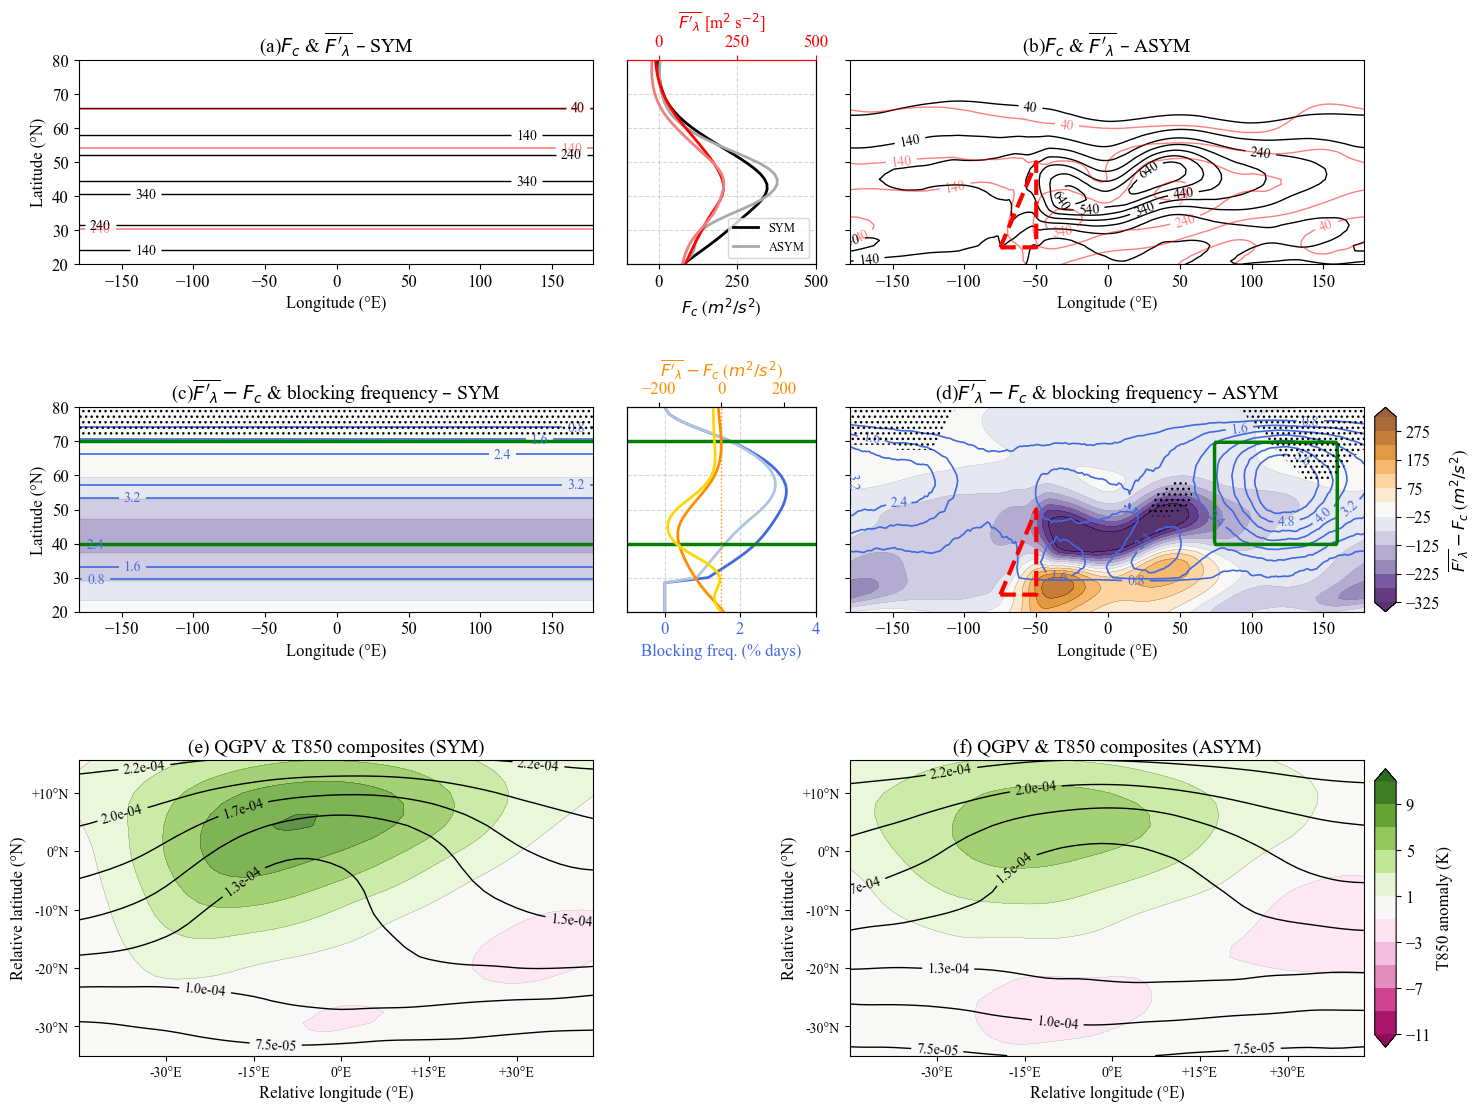

In [28]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D

plt.rcParams['font.size'] = 12

# Assumes ds_clims, ds_composites and define_mask() are already defined.

# --------------------------------------------------
# Helpers
# --------------------------------------------------
def zonal2d(da):
    """Zonal mean broadcast back onto the 2D (lat, lon) grid -> zonally symmetric field."""
    return da.mean('lon').broadcast_like(da).transpose(*da.dims)

def add_hatch(ax, lon, lat, mask):
    hatch_mask = np.where(mask, 1, np.nan)
    ax.contourf(lon, lat, hatch_mask, levels=[0.5, 1.5],
                hatches=['...', None], colors='none', alpha=0, zorder=10)

def style_map(ax, is_left):
    ax.set_ylim(20, 80)
    ax.set_xlabel('Longitude (°E)')
    if is_left:
        ax.set_ylabel('Latitude (°N)')
    else:
        plt.setp(ax.get_yticklabels(), visible=False)

# --------------------------------------------------
# Data
# --------------------------------------------------
SYM  = ds_clims[0]
ASYM = ds_clims[2]

lat = SYM['FC']['lat'].values
lon = SYM['FC']['lon'].values

FC_s,  FC_a  = SYM['FC'],  ASYM['FC']
Fl_s,  Fl_a  = SYM['CLIM_transient_flux'], ASYM['CLIM_transient_flux']
bf_s,  bf_a  = SYM['block_freq'], ASYM['block_freq']
diff_s, diff_a = Fl_s - FC_s, Fl_a - FC_a

r_mask_a = ASYM['r_mask']
# SYM: latitudes where r_mask holds for most longitudes, made zonally symmetric
r_mask_s = zonal2d(SYM['r_mask'].astype(float)) > 0.5

mask_asymmetric = define_mask(40, 70, 75, 160)

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons_closed = lons + (lons[0],)
lats_closed = lats + (lats[0],)

FC_levels       = np.arange(40, 1300, 100)
block_levels    = np.arange(0.8, 6, 0.8)
diff_levels     = np.arange(-325, 330, 50)
t850_ano_levels = np.arange(-11, 12, 2)

letters = {'a': '(a)', 'b': '(b)', 'c': '(c)', 'd': '(d)'}

# --------------------------------------------------
# Figure layout
# columns: map | gap | zonal mean | gap | map | colorbar
# --------------------------------------------------
fig = plt.figure(figsize=(17, 13))
gs = gridspec.GridSpec(
    nrows=3, ncols=6,
    width_ratios=[6.0, 0.15, 2.2, 0.15, 6.0, 0.25],
    height_ratios=[1.0, 1.0, 1.5],
    hspace=0.6, wspace=0.05
)

# centre (zonal-mean) axes first, so the maps can share their y-axis
ax_c1 = fig.add_subplot(gs[0, 2])
ax_c2 = fig.add_subplot(gs[1, 2])

ax_l1 = fig.add_subplot(gs[0, 0], sharey=ax_c1)
ax_r1 = fig.add_subplot(gs[0, 4], sharey=ax_c1)
ax_l2 = fig.add_subplot(gs[1, 0], sharey=ax_c2)
ax_r2 = fig.add_subplot(gs[1, 4], sharey=ax_c2)

cax_r2 = fig.add_subplot(gs[1, 5])   # dedicated colorbar axis, row 2
cax_r3 = fig.add_subplot(gs[2, 5])   # dedicated colorbar axis, row 3

# ==================================================
# ROW 1 — Fc & F_lambda
# ==================================================
# --- left: SYM (zonally symmetric) ---
c  = ax_l1.contour(lon, lat, zonal2d(FC_s), FC_levels, colors='k', linewidths=1)
c2 = ax_l1.contour(lon, lat, zonal2d(Fl_s), FC_levels, colors='red', alpha=0.5, linewidths=1.2)
ax_l1.clabel(c, colors='k', fmt='%d', fontsize=10)
ax_l1.clabel(c2, colors='red', fmt='%d', fontsize=10)
ax_l1.set_title(f"{letters["a"]}" + r"$F_c$ & $\overline{F'_{\lambda}}$ – SYM")
style_map(ax_l1, True)

# --- right: ASYM ---
c  = ax_r1.contour(lon, lat, FC_a, FC_levels, colors='k', linewidths=1)
c2 = ax_r1.contour(lon, lat, Fl_a, FC_levels, colors='red', alpha=0.5, linewidths=1)
ax_r1.plot(lons_closed, lats_closed, '--', lw=3, color='red')
ax_r1.clabel(c, colors='k', fmt='%d', fontsize=10)
ax_r1.clabel(c2, colors='red', fmt='%d', fontsize=10)
ax_r1.set_title(f"{letters["b"]}" + r"$F_c$ & $\overline{F'_{\lambda}}$ – ASYM")
style_map(ax_r1, False)

# --- centre: zonal means, dark = SYM, light = ASYM ---
ax_c1_twin = ax_c1.twiny()   # second x-axis (top) for F_lambda
for ds_fc, ds_fl, c_fc, c_fl in [(FC_s, Fl_s, 'k', 'red'),
                                 (FC_a, Fl_a, 'darkgray', 'lightcoral')]:   # SYM dark, ASYM light
    ax_c1.plot(ds_fc.mean('lon'), lat, color=c_fc, lw=2)         # F_c: bottom axis
    ax_c1_twin.plot(ds_fl.mean('lon'), lat, color=c_fl, lw=2)    # F_lambda: top axis

# F_c — bottom axis, k
ax_c1.set_xlim(-100, 500)
ax_c1.set_xticks([0, 250, 500])
ax_c1.set_xlabel(r'$F_c$ ($m^2/s^2$)', color='k')
ax_c1.tick_params(axis='x', labelcolor='k', color='k')
ax_c1.spines['bottom'].set_color('k')

# F_lambda — top axis, red
ax_c1_twin.set_xlim(-100, 500)
ax_c1_twin.set_xticks([0, 250, 500])
ax_c1_twin.set_xlabel(r"$\overline{F'_{\lambda}}$ [m$^2$ s$^{-2}$]", color='red')
ax_c1_twin.tick_params(axis='x', labelcolor='red', color='red')
ax_c1_twin.spines['top'].set_color('red')

#ax_c1.set_title('Zonal mean', pad=40)   # room for the top axis label
ax_c1.grid(True, ls='--', alpha=0.5)
ax_c1.tick_params(axis='y', length=0)
plt.setp(ax_c1.get_yticklabels(), visible=False)
ax_c1_twin.legend(handles=[Line2D([], [], color='k',        lw=2, label='SYM'),
                           Line2D([], [], color='darkgray', lw=2, label='ASYM')],
                  loc='lower right', fontsize=9)

# ==================================================
# ROW 2 — (F_lambda - Fc) & blocking frequency
# ==================================================
# --- left: SYM (zonally symmetric) ---
diff_s2d = zonal2d(diff_s)
ax_l2.contourf(lon, lat, diff_s2d, levels=diff_levels,
               extend='both', alpha=0.8, cmap='PuOr_r')
ax_l2.contour(lon, lat, diff_s2d, levels=diff_levels, colors='k', linewidths=0.1)
cb = ax_l2.contour(lon, lat, zonal2d(bf_s), levels=block_levels,
                   colors='royalblue', linewidths=1.2)
ax_l2.clabel(cb, colors='royalblue', fmt='%.1f', fontsize=10)
ax_l2.axhline(40, color='green', lw=2.5)
ax_l2.axhline(70, color='green', lw=2.5)
add_hatch(ax_l2, lon, lat, r_mask_s)
ax_l2.set_title(f"{letters["c"]}" +  r"$\overline{F'_{\lambda}} - F_c$ & blocking frequency – SYM")
style_map(ax_l2, True)

# --- right: ASYM ---
cf = ax_r2.contourf(lon, lat, diff_a, levels=diff_levels,
                    extend='both', alpha=0.8, cmap='PuOr_r')
ax_r2.contour(lon, lat, diff_a, levels=diff_levels, colors='k', linewidths=0.1)
cb = ax_r2.contour(lon, lat, bf_a, levels=block_levels,
                   colors='royalblue', linewidths=1.2)
ax_r2.clabel(cb, colors='royalblue', fmt='%.1f', fontsize=10)
ax_r2.contour(lon, lat, mask_asymmetric, levels=[0.5, 1.5], colors='green', linewidths=2.5)
add_hatch(ax_r2, lon, lat, r_mask_a)
ax_r2.plot(lons_closed, lats_closed, '--', lw=3, color='red')
fig.colorbar(cf, cax=cax_r2, label=r"$\overline{F'_{\lambda}} - F_c$ ($m^2/s^2$)")
ax_r2.set_title(f"{letters["d"]}" + r"$\overline{F'_{\lambda}} - F_c$ & blocking frequency – ASYM")
style_map(ax_r2, False)

# --- centre: zonal means, dark = SYM, light = ASYM ---
ax_c2_twin = ax_c2.twiny()
for diff, bf, c_bf, c_diff in [(diff_s, bf_s, 'royalblue', 'darkorange'),
                               (diff_a, bf_a, 'lightsteelblue', 'gold')]:   # SYM dark, ASYM light
    ax_c2.plot(bf.mean('lon'), lat, color=c_bf, lw=2)
    ax_c2_twin.plot(diff.mean('lon'), lat, color=c_diff, lw=2)

ax_c2.set_xlabel('Blocking freq. (% days)', color='royalblue')
ax_c2.tick_params(axis='x', labelcolor='royalblue')
ax_c2.set_xlim(-1, 4)
ax_c2.set_xticks([0, 2, 4])
ax_c2.set_ylim(20, 80)

ax_c2_twin.axvline(0, color='darkorange', ls=':', lw=1)
ax_c2_twin.set_xlabel(r"$\overline{F'_{\lambda}} - F_c$ ($m^2/s^2$)", color="darkorange")
ax_c2_twin.tick_params(axis='x', labelcolor='darkorange')
ax_c2_twin.set_xlim(-300, 300)    # adjust to your data range
ax_c2_twin.set_xticks([-200, 0, 200])

ax_c2.axhline(40, color='green', lw=2.5)
ax_c2.axhline(70, color='green', lw=2.5)
ax_c2.grid(True, ls='--', alpha=0.5)
ax_c2.tick_params(axis='y', length=0)
plt.setp(ax_c2.get_yticklabels(), visible=False)
#ax_c2.set_title('Zonal mean', pad=40)

# ==================================================
# ROW 3 — Composites (unchanged, centre column empty)
# ==================================================
ax_comp = [fig.add_subplot(gs[2, 0]), fig.add_subplot(gs[2, 4])]
exp_names    = ['SYM', 'ASYM']
comp_letters = ['(e)', '(f)']

for j, i in enumerate([0, 2]):
    comp_qgpv     = ds_composites[i]['composite_qgpv']
    comp_t850_ano = ds_composites[i]['composite_t850_ano']

    pcm = ax_comp[j].contourf(
        comp_t850_ano['lon'], comp_t850_ano['lat'], comp_t850_ano,
        t850_ano_levels, extend='both', alpha=0.8, cmap='PiYG'
    )
    ax_comp[j].contour(
        comp_t850_ano['lon'], comp_t850_ano['lat'], comp_t850_ano,
        t850_ano_levels, colors='k', linewidths=0.1
    )
    """
    if j == 0:
        # left composite: colorbar steals from its own axes (harmless with set_aspect(1))
        fig.colorbar(pcm, ax=ax_comp[j], orientation='vertical', label='T850 anomaly (K)')
    else:
        # right composite: dedicated colorbar axis, aligned with the one above
        fig.colorbar(pcm, cax=cax_r3, label='T850 anomaly (K)')
    """
    fig.colorbar(pcm, cax=cax_r3, label='T850 anomaly (K)')

    cs = ax_comp[j].contour(
        comp_qgpv['lon'], comp_qgpv['lat'], comp_qgpv,
        colors='k', linewidths=1
    )
    ax_comp[j].clabel(cs, colors='k', fmt='%.1e', fontsize=10)

    ax_comp[j].set_xticks([12, 24, 36, 48, 60])
    ax_comp[j].set_yticks([4, 12, 20, 28, 36])
    ax_comp[j].set_xticklabels(['-30°E', '-15°E', '0°E', '+15°E', '+30°E'], fontsize=10)
    ax_comp[j].set_yticklabels(['-30°N', '-20°N', '-10°N', '0°N', '+10°N'], fontsize=10)
    ax_comp[j].set_title(f'{comp_letters[j]} QGPV & T850 composites ({exp_names[j]})')
    ax_comp[j].set_xlabel('Relative longitude (°E)')
    ax_comp[j].set_ylabel('Relative latitude (°N)')
    ax_comp[j].set_aspect(1)

plt.savefig('PLOTS/Figure_3.png', dpi=300, bbox_inches='tight')
plt.show()